# 06 – Aplicação estratégica: risco de metas, prioridades e perfis de municípios

Os notebooks anteriores explicam o resultado do **aluno**. Este muda o foco para o **município**, onde a
gestão pública age, e transforma os modelos em apoio à decisão.

**Perguntas de negócio**

| Pergunta | Abordagem |
|---|---|
| Quais municípios podem não atingir a meta de 2025? | Modelo que prevê a taxa do ano seguinte e a probabilidade de ela ficar abaixo da meta (treinado com 2023 → 2024 e aplicado a 2024 → 2025) |
| Quais municípios apresentam maior risco educacional? | Matriz de prioridade: nível atual × risco de não atingir a meta |
| Quais regiões possuem padrões semelhantes? | Agrupamento de municípios por perfil (K-Means) |

**Bases:** `base_municipios_2023` (treino, com o resultado de 2024 conhecido) e `base_municipios_2024`
(projeção para 2025). O código do modelo municipal está em `src/modeling/municipios.py`.

**Entregas:** `reports/ranking_prioridade_municipios_2025.csv` (ranking de prioridade) e
`reports/municipios_risco_perfil_2025.csv` (base consolidada para painéis).

> **Pré-requisito:** rode os notebooks 01 e 02 antes deste.

> **Como ler as projeções:** o risco de 2025 é uma **estimativa** baseada na dinâmica observada entre 2023 e
> 2024, não um resultado. A incerteza é maior em municípios pequenos e no Rio Grande do Sul, afetado pelo
> choque de 2024.

In [1]:
# Configura o caminho do projeto para importar os módulos de src/.
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", None)
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.metrics import roc_auc_score, brier_score_loss, mean_absolute_error, r2_score
from lightgbm import LGBMRegressor
import shap

from src.config import RANDOM_STATE, REPORTS_DIR
from src.modeling.pipeline import criar_pipeline, modelos_candidatos
from src.modeling.municipios import (NUM_MUNICIPIO, CAT_MUNICIPIO, CAT_MUNICIPIO_COM_UF, ALVO_MUNICIPIO, VAZAMENTO_MUNICIPIO,
                                     VARS_CLUSTER, pipeline_cluster, escolher_k, perfil_clusters,
                                     nomear_clusters, prioridade, NUM_PROJECAO, CAT_PROJECAO,
                                     RiscoMetaRegressao)
from src.modeling.train import avaliar_cv, otimizar, ESPACO_LOGISTICA, ESPACO_LGBM, salvar_modelo, bootstrap_metrica
from src.evaluation.metrics import resumo_cv, metricas, grafico_avaliacao
from src.visualization.style import (aplicar_estilo, salvar, AZUL, AZUL_ESCURO, AZUL_MEDIO, AZUL_CLARO, LARANJA,
                                     VERMELHO, CINZA, TEXTO_2, SEQ_AZUL)
from src.visualization.rotulos import rotulo
aplicar_estilo()

treino_mun = pd.read_parquet(ROOT / "data/processed/base_municipios_2023.parquet")   # 2023 -> meta 2024 (alvo observado)
projecao_mun = pd.read_parquet(ROOT / "data/processed/base_municipios_2024.parquet") # 2024 -> meta 2025 (alvo futuro)
X = treino_mun[NUM_MUNICIPIO + CAT_MUNICIPIO]
y = treino_mun[ALVO_MUNICIPIO]
print(f"Municípios com meta 2024: {len(X):,} | não atingiram: {y.mean():.1%}")
print("Colunas do desfecho excluídas das variáveis:", VAZAMENTO_MUNICIPIO)

Municípios com meta 2024: 5,232 | não atingiram: 46.7%
Colunas do desfecho excluídas das variáveis: ['taxa_proximo_ano', 'meta_ano', 'status_meta', 'nao_atingiu_meta']


## 1. Primeira abordagem: classificador direto “não atingiu a meta”

**Desenho temporal (anti-leakage):** as variáveis descrevem o município **em 2023** (resultado, participação,
posição em relação à UF, meta exigida e contexto socioeconômico); o alvo é **não ter atingido a meta em
2024**. A ideia é depois aplicar o modelo às variáveis **de 2024** para estimar o risco em relação à
**meta de 2025** – o uso que um gestor faria no início de cada ano.

Como cada município aparece uma vez, a validação é K-Fold estratificado (5 folds), com 20% reservados
para teste.

In [2]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
cands = modelos_candidatos()
cands["LightGBM"].set_params(min_child_samples=30)
cands["Random Forest"].set_params(min_samples_leaf=10)
res = {n: avaliar_cv(criar_pipeline(m, NUM_MUNICIPIO, CAT_MUNICIPIO), X_tr, y_tr, cv=cv)
       for n, m in cands.items()}
tab = resumo_cv(res)
tab.to_csv(REPORTS_DIR / "comparacao_modelos_municipio_cv.csv")
tab[["roc_auc", "pr_auc", "brier", "balanced_acc", "roc_auc_treino", "gap_overfitting"]].round(4)

,roc_auc,pr_auc,brier,balanced_acc,roc_auc_treino,gap_overfitting
modelo,,,,,,
Regressão Logística,0.7545 ± 0.0111,0.7173 ± 0.0145,0.2006 ± 0.0043,0.6871 ± 0.0099,0.7693,0.0148
Random Forest,0.7837 ± 0.0121,0.7670 ± 0.0160,0.1912 ± 0.0037,0.7053 ± 0.0105,0.9610,0.1773
HistGradientBoosting,0.7730 ± 0.0196,0.7532 ± 0.0166,0.1977 ± 0.0104,0.6951 ± 0.0215,0.9964,0.2234
XGBoost,0.7808 ± 0.0144,0.7640 ± 0.0157,0.1894 ± 0.0061,0.6990 ± 0.0201,0.8989,0.1181
LightGBM,0.7785 ± 0.0177,0.7625 ± 0.0151,0.1916 ± 0.0082,0.6950 ± 0.0214,0.9698,0.1913


**Leitura**
- **Os modelos de árvore (≈0,78) superam a Regressão Logística (≈0,75)**, o que sugere relações não
  lineares e interações relevantes no nível do município.
- **A diferença entre treino e validação das árvores é grande** (de 0,12 a 0,22). A métrica de validação é
  a que mede a generalização, mas essa diferença indica espaço para regularizar mais, o que é feito na
  abordagem adotada (seção 2).

### UF como variável categórica: ganho real ou memorização de um choque?

A EDA e a interpretabilidade do modelo de alunos mostraram que o **Rio Grande do Sul** despencou em 2024
(63% → 45% no estado), queda que coincide com as **enchentes de abril–maio de 2024**. Com apenas uma
transição (2023 → 2024) para treinar, um dummy de UF pode simplesmente **memorizar esse choque** – e
projetá-lo para 2025 como se fosse uma característica permanente do estado. Testamos isso:

In [3]:
from sklearn.model_selection import cross_val_score
log_ref = modelos_candidatos()["Regressão Logística"]
comparacao_uf = {}
for nome, cats in [("Com dummies de UF e região", CAT_MUNICIPIO_COM_UF), ("Sem dummies (contexto estadual contínuo)", CAT_MUNICIPIO)]:
    Xa = treino_mun[NUM_MUNICIPIO + cats]
    auc_cv = cross_val_score(criar_pipeline(log_ref, NUM_MUNICIPIO, cats), Xa, y, cv=cv, scoring="roc_auc").mean()
    # Experimento: treinar SEM o RS e prever o RS (o choque era previsível com dados de 2023?)
    fora = treino_mun["sigla_uf"] != "RS"
    m = criar_pipeline(log_ref, NUM_MUNICIPIO, cats).fit(Xa[fora], y[fora])
    p_rs = m.predict_proba(Xa[~fora])[:, 1]
    comparacao_uf[nome] = {"ROC-AUC CV": auc_cv, "RS: risco médio previsto (treino sem RS)": p_rs.mean(),
                           "RS: % real que não atingiu a meta": y[~fora].mean()}
pd.DataFrame(comparacao_uf).T.round(3)

,ROC-AUC CV,RS: risco médio previsto (treino sem RS),RS: % real que não atingiu a meta
Com dummies de UF e região,0.795,0.452,0.905
Sem dummies (contexto estadual contínuo),0.761,0.450,0.905


**Leitura**
- **Com os indicadores de UF e região, a ROC-AUC sobe** (0,795 contra 0,761). Parte desse ganho
  provavelmente vem de o modelo saber, a posteriori, que o RS e a BA foram mal em 2024: 90% e 81% dos
  municípios, respectivamente, não atingiram a meta.
- **Quando o RS fica fora do treino, nenhum dos modelos antecipa a queda:** o risco previsto para o estado
  é de cerca de 45%, contra 90% de municípios gaúchos que de fato não atingiram a meta. Os dados de 2023 não
  traziam sinal desse choque, o que é compatível com um evento externo.
- **Decisão:** para projetar 2025, os modelos usam o contexto estadual de forma contínua (taxa da UF e
  distância do município para ela), sem indicadores de UF e região. São um pouco menos precisos no passado,
  mas evitam levar para o futuro um choque de um único ano.

### Problema para projetar 2025: as metas mudam de escala

O classificador aprende a relação entre o **esforço exigido** (meta − taxa atual) e o resultado. Em 2024,
esse esforço foi pequeno (no máximo 7 pontos), o que indica que as metas de 2024 partiram do resultado de
2023. Para 2025, a meta segue a trajetória até 2030 enquanto a taxa de 2024 oscilou, e o esforço exigido
muda completamente de escala:

Municípios com esforço para 2025 acima do máximo visto no treino: 35%


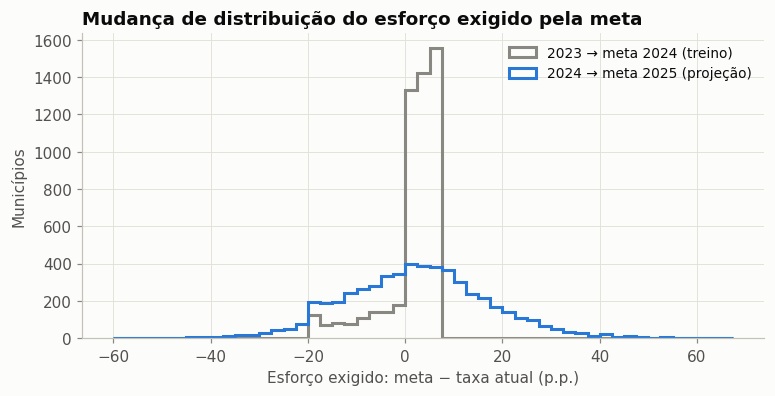

,2023 → meta 2024 (treino),2024 → meta 2025 (projeção)
count,5232.0,5352.0
mean,1.7,2.2
std,5.8,14.8
min,-32.0,-76.3
25%,0.7,-7.6
50%,3.1,2.2
75%,5.4,11.3
max,7.2,68.9


In [4]:
esf = pd.DataFrame({"2023 → meta 2024 (treino)": treino_mun["esforco_meta"].describe(),
                    "2024 → meta 2025 (projeção)": projecao_mun["esforco_meta"].describe()}).round(1)
fora = (projecao_mun["esforco_meta"] > treino_mun["esforco_meta"].max()).mean()
print(f"Municípios com esforço para 2025 acima do máximo visto no treino: {fora:.0%}")
fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.arange(-60, 70, 2.5)
ax.hist(treino_mun["esforco_meta"].dropna(), bins=bins, histtype="step", linewidth=2, color=CINZA, label="2023 → meta 2024 (treino)")
ax.hist(projecao_mun["esforco_meta"].dropna(), bins=bins, histtype="step", linewidth=2, color=AZUL, label="2024 → meta 2025 (projeção)")
ax.set_xlabel("Esforço exigido: meta − taxa atual (p.p.)"); ax.set_ylabel("Municípios")
ax.set_title("Mudança de distribuição do esforço exigido pela meta"); ax.legend()
salvar(fig, "estrategia_02_mudanca_esforco")
plt.show()
esf

**35% dos municípios ficam fora da faixa de esforço vista no treino.** O classificador estaria
extrapolando justamente nos casos mais importantes. Por isso foi adotada uma segunda abordagem.

## 2. Abordagem adotada: prever a taxa do ano seguinte e comparar com a meta

1. Um **regressor** (LightGBM em pipeline) prevê a taxa do ano seguinte a partir dos indicadores do ano
   atual, **sem usar a meta como variável**.
2. A incerteza vem dos **erros fora da amostra**, calculados por porte de município (municípios pequenos
   variam mais).
3. **Risco = P(taxa < meta) = Φ((meta − taxa prevista) / σ do porte).** Essa conta supõe que os erros
   seguem, aproximadamente, uma distribuição normal.

Assim, a mesma lógica vale para **qualquer meta futura** (2025, 2026…), sem extrapolar.

**Tratamento do choque de 2024:** os municípios do **RS** ficam fora do *treino*, porque a transição
2023 → 2024 deles provavelmente reflete as enchentes, e não a dinâmica normal de um ano letivo. Eles
continuam sendo **projetados** para 2025, com um alerta de incerteza adicional.

In [5]:
regressor = LGBMRegressor(n_estimators=600, learning_rate=0.02, num_leaves=8, min_child_samples=100,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.6, reg_lambda=5.0,
                          verbose=-1, n_jobs=1, random_state=RANDOM_STATE)
base_reg = treino_mun.dropna(subset=["taxa_proximo_ano"])
base_reg = base_reg[base_reg["sigla_uf"] != "RS"]
Xr = base_reg[NUM_PROJECAO + CAT_PROJECAO]
yr = base_reg["taxa_proximo_ano"]
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, random_state=RANDOM_STATE,
                                              stratify=base_reg[ALVO_MUNICIPIO])
proj_model = RiscoMetaRegressao(criar_pipeline(regressor, NUM_PROJECAO, CAT_PROJECAO)).fit(Xr_tr, yr_tr)

te_reg = base_reg.loc[Xr_te.index]
taxa_prev = proj_model.prever_taxa(Xr_te)
risco_te = proj_model.risco(Xr_te, te_reg["meta_ano"])
print(f"Taxa do ano seguinte – MAE: {mean_absolute_error(yr_te, taxa_prev):.2f} p.p. | R²: {r2_score(yr_te, taxa_prev):.3f}")
print(f"  (referência ingênua 'repetir a taxa atual': MAE {mean_absolute_error(yr_te, te_reg['taxa_atual']):.2f} | R² {r2_score(yr_te, te_reg['taxa_atual']):.3f})")
print(f"Não atingir a meta – ROC-AUC: {roc_auc_score(te_reg[ALVO_MUNICIPIO], risco_te):.3f} | Brier: {brier_score_loss(te_reg[ALVO_MUNICIPIO], risco_te):.3f}")
print("Incerteza (σ dos resíduos, p.p.) por porte:")
proj_model.sigma_porte_.round(2)

Taxa do ano seguinte – MAE: 8.32 p.p. | R²: 0.658
  (referência ingênua 'repetir a taxa atual': MAE 11.55 | R² 0.318)
Não atingir a meta – ROC-AUC: 0.781 | Brier: 0.189
Incerteza (σ dos resíduos, p.p.) por porte:


porte_municipio
100–500 mil         5.68
20–100 mil          8.30
5–20 mil           11.68
Até 5 mil          14.88
Mais de 500 mil     5.88
Name: taxa_proximo_ano, dtype: float64

In [6]:
# Comparação justa, no MESMO teste (sem RS): classificador direto (Random Forest) x abordagem por regressão.
clf = criar_pipeline(cands["Random Forest"], NUM_MUNICIPIO, CAT_MUNICIPIO)
clf.fit(base_reg.loc[Xr_tr.index, NUM_MUNICIPIO + CAT_MUNICIPIO], base_reg.loc[Xr_tr.index, ALVO_MUNICIPIO])
p_clf = clf.predict_proba(te_reg[NUM_MUNICIPIO + CAT_MUNICIPIO])[:, 1]
y_meta = te_reg[ALVO_MUNICIPIO]
comp = pd.DataFrame({"Classificador direto (RF)": metricas(y_meta, p_clf),
                     "Regressão + probabilidade (adotado)": metricas(y_meta, risco_te)}).T
ic = bootstrap_metrica(y_meta, risco_te, roc_auc_score, n=500)
print(f"IC 95% da ROC-AUC da abordagem adotada: {ic[0]:.3f}–{ic[2]:.3f}")
comp[["ROC-AUC", "PR-AUC", "Brier", "Acurácia balanceada", "F1"]].round(3)

IC 95% da ROC-AUC da abordagem adotada: 0.752–0.809


,ROC-AUC,PR-AUC,Brier,Acurácia balanceada,F1
Classificador direto (RF),0.780,0.705,0.194,0.685,0.607
Regressão + probabilidade (adotado),0.781,0.714,0.189,0.691,0.630


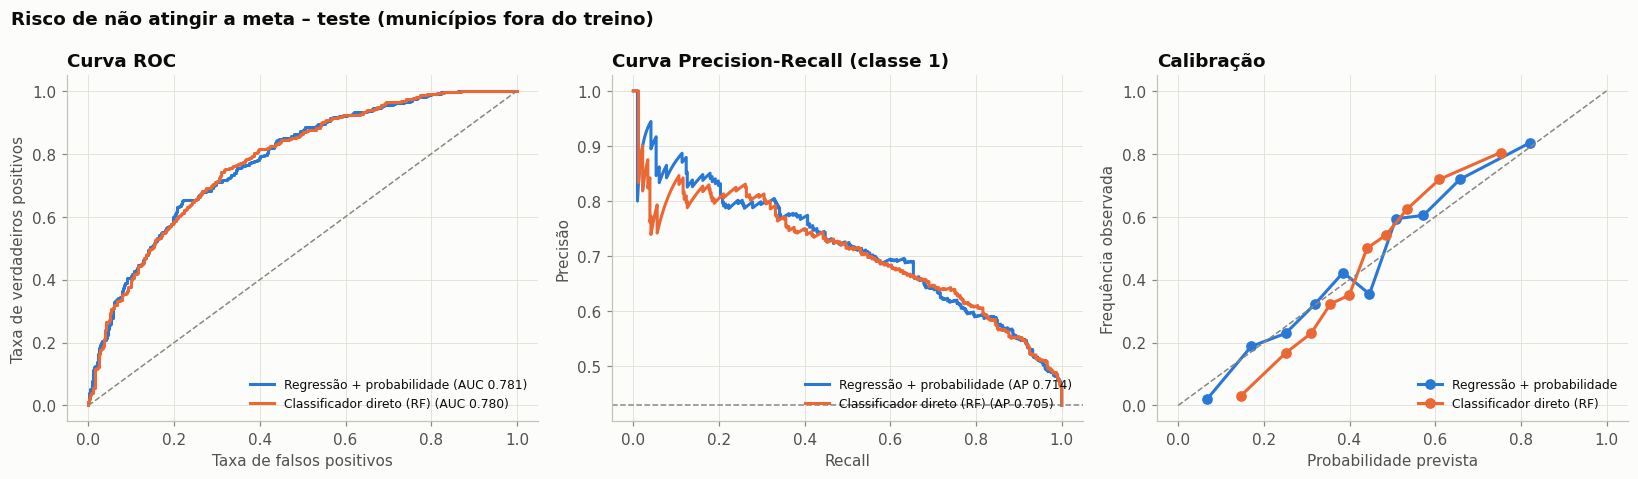

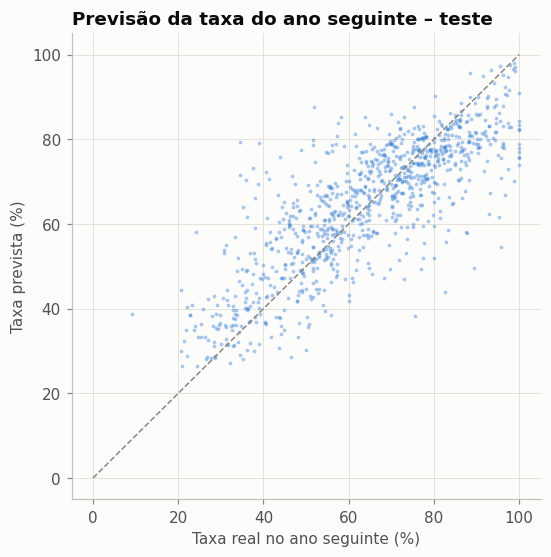

In [7]:
fig = grafico_avaliacao(y_meta, {"Regressão + probabilidade": risco_te, "Classificador direto (RF)": p_clf},
                        "Risco de não atingir a meta – teste (municípios fora do treino)")
salvar(fig, "estrategia_01_avaliacao_risco_meta")
plt.show()
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(yr_te, taxa_prev, s=6, alpha=0.4, color=AZUL, linewidths=0)
ax.plot([0, 100], [0, 100], color=CINZA, linestyle="--", linewidth=1)
ax.set_xlabel("Taxa real no ano seguinte (%)"); ax.set_ylabel("Taxa prevista (%)")
ax.set_title("Previsão da taxa do ano seguinte – teste")
salvar(fig, "estrategia_02b_previsao_taxa")
plt.show()

**Leitura**
- **A abordagem por regressão empata com o classificador direto** em identificar quem não atinge a meta
  (ROC-AUC de 0,781 contra 0,780). Além disso, entrega a **taxa prevista**, um número que o gestor entende,
  e funciona para qualquer meta futura.
- **O erro médio é de 8,3 pontos na taxa do ano seguinte**, e o modelo explica 66% da variação (R²). Isso é
  bem melhor que supor que a taxa se repete (erro de 11,6 pontos e R² de 0,32). O erro é maior em municípios
  pequenos, e isso já entra no cálculo do risco.
- **As probabilidades ficaram razoavelmente calibradas no teste:** entre os municípios com risco previsto
  em torno de 70%, aproximadamente 7 em cada 10 não atingiram a meta.

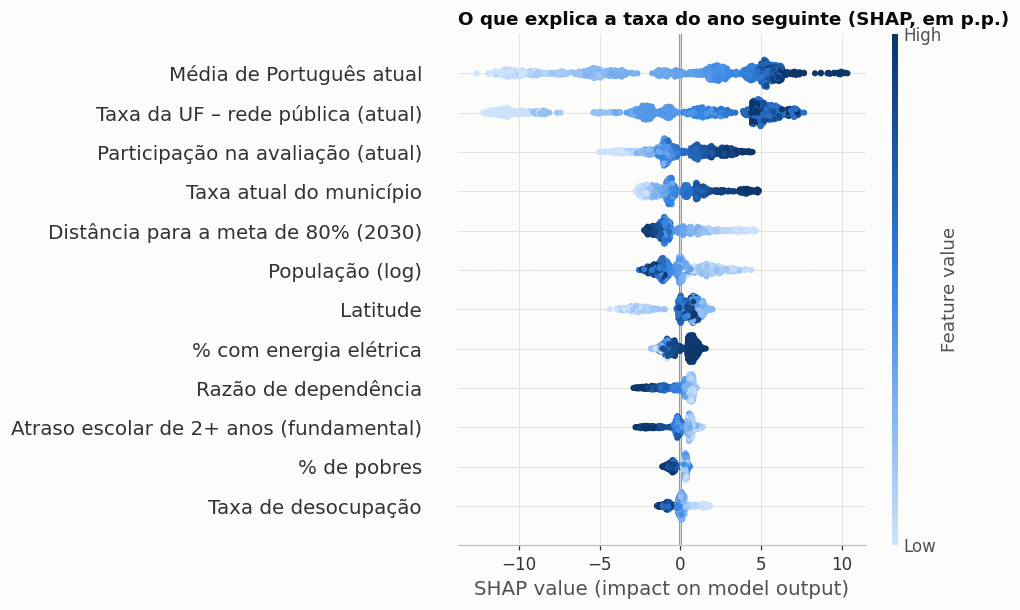

CPU times: total: 3.09 s
Wall time: 861 ms


,média |SHAP| (p.p.)
media_atual,5.06
taxa_uf_publica_atual,4.74
participacao_atual,1.66
taxa_atual,1.45
distancia_meta_2030,1.34
log_populacao,1.11
latitude,1.06
pct_energia_eletrica,0.76
razao_dependencia,0.75
taxa_atraso_2anos_fund,0.61


In [8]:
%%time
# O que move a taxa do ano seguinte? SHAP do regressor (em p.p. de taxa).
reg_fit = proj_model.pipeline
Zr = pd.DataFrame(reg_fit[:-1].transform(Xr_te), columns=reg_fit.named_steps["preprocessamento"].get_feature_names_out(),
                  index=Xr_te.index)
sv = shap.TreeExplainer(reg_fit.named_steps["modelo"]).shap_values(Zr)
imp = pd.Series(np.abs(sv).mean(axis=0), index=Zr.columns)
imp = imp.groupby(imp.index.str.replace("missingindicator_", "").str.replace(r"^porte_municipio_.*", "porte_municipio", regex=True)).sum()
top = imp.sort_values(ascending=False).head(12)
plt.figure()
cols = [c for c in top.index if c in Zr.columns]
shap.summary_plot(sv[:, [list(Zr.columns).index(c) for c in cols]], Zr[cols], feature_names=[rotulo(c) for c in cols], show=False, cmap=SEQ_AZUL, plot_size=(9, 5.5))
plt.title("O que explica a taxa do ano seguinte (SHAP, em p.p.)", loc="left", fontweight="bold")
salvar(plt.gcf(), "estrategia_03_shap_projecao")
plt.show()
top.round(2).to_frame("média |SHAP| (p.p.)")

**O que move a taxa do ano seguinte**
- **O desempenho atual do município** (média de Português e taxa): municípios com resultado alto hoje
  tendem a ter resultado alto no ano seguinte.
- **O nível do estado** (`taxa_uf_publica_atual`) é o segundo fator: estar num estado com bom desempenho se
  associa a taxas maiores, além do próprio resultado do município. Uma explicação possível é o efeito de
  políticas estaduais.
- **Regressão à média:** o modelo associa avanço maior aos municípios mais distantes de 80%
  (`distancia_meta_2030` alta, ou seja, taxa atual baixa) e um leve recuo aos resultados muito altos.
- **Participação alta na avaliação** se associa a taxas futuras maiores, e municípios **maiores**
  (`log_populacao`) avançaram menos que os pequenos, em média.
- **O contexto socioeconômico** (dependência demográfica, distorção idade-série, pobreza, desocupação) tem
  peso menor, no sentido esperado.

## 3. Projeção: risco de não atingir a meta de 2025

O modelo é reajustado com todos os municípios (exceto o RS) e aplicado aos indicadores de 2024.

In [9]:
proj_model = RiscoMetaRegressao(criar_pipeline(regressor, NUM_PROJECAO, CAT_PROJECAO)).fit(Xr, yr)
salvar_modelo(proj_model, "modelo_projecao_meta_municipio", {
    "abordagem": "LightGBM regressor da taxa do ano seguinte + P(taxa < meta) com sigma por porte",
    "treino": "indicadores 2023 -> taxa 2024 (exceto RS, choque das enchentes)",
    "sigma_por_porte": proj_model.sigma_porte_.round(3).to_dict()})

proj = projecao_mun.dropna(subset=["meta_alvo", "taxa_atual"]).copy()
Xp = proj[NUM_PROJECAO + CAT_PROJECAO]
proj["taxa_prevista_2025"] = proj_model.prever_taxa(Xp)
proj["risco_meta_2025"] = proj_model.risco(Xp, proj["meta_alvo"])
proj["faixa_risco"] = pd.cut(proj["risco_meta_2025"], [0, 0.3, 0.5, 0.7, 1.0001],
                             labels=["Baixo", "Moderado", "Alto", "Muito alto"], include_lowest=True)
proj["obs"] = np.where(proj["sigla_uf"] == "RS", "Incerteza adicional: recuperação pós-enchentes", "")

brasil = pd.read_parquet(ROOT / "data/processed/gold_brasil_desempenho.parquet").set_index("ano")
print(f"Municípios projetados: {len(proj):,}")
print(f"Taxa média prevista para 2025 (média simples dos municípios): {proj['taxa_prevista_2025'].mean():.1f}%")
print(f"Resultado nacional REAL de 2025 da rede pública (INEP): {brasil.loc[2025, 'taxa_alfabetizacao']:.1f}%  <- checagem de coerência")
print(f"Chance média de não atingir a meta de 2025: {proj['risco_meta_2025'].mean():.1%}")
proj["faixa_risco"].value_counts().sort_index().to_frame("municípios")

Municípios projetados: 5,352
Taxa média prevista para 2025 (média simples dos municípios): 67.1%
Resultado nacional REAL de 2025 da rede pública (INEP): 66.0%  <- checagem de coerência
Chance média de não atingir a meta de 2025: 45.8%


,municípios
faixa_risco,
Baixo,1999
Moderado,1057
Alto,856
Muito alto,1440


**Checagem de ordem de grandeza:** a base traz o resultado **nacional** de 2025 (66%), que não foi usado no
treino. A média prevista para os municípios (67%) ficou próxima desse valor. É um indício, não uma
validação: as duas médias medem coisas diferentes (a nacional é ponderada pelo número de alunos e inclui a
rede estadual), e o resultado de 2025 por município ainda não está disponível para conferir as previsões.

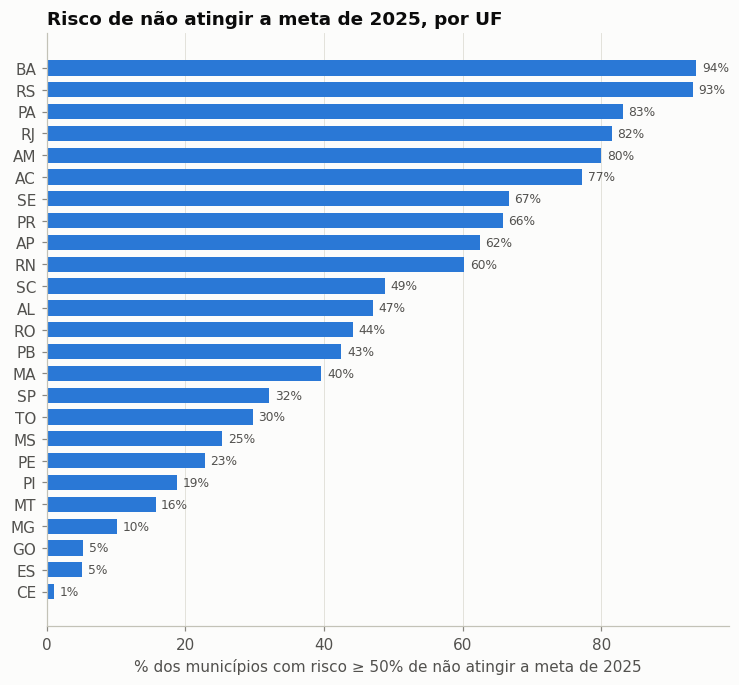

,municipios,pct_risco_alto,risco_medio,taxa_2024,taxa_prevista_2025,meta_2025
sigla_uf,,,,,,
BA,398,0.94,0.83,36.65,38.02,50.22
RS,441,0.93,0.84,52.94,58.49,72.79
PA,142,0.83,0.75,48.83,49.40,56.63
RJ,92,0.82,0.67,58.74,60.03,63.50
AM,55,0.80,0.77,45.00,46.40,55.99
AC,22,0.77,0.60,43.50,47.78,49.91
SE,75,0.67,0.60,36.45,41.13,43.90
PR,398,0.66,0.59,74.04,73.37,75.47


In [10]:
# Risco por UF: % de municípios com risco alto ou muito alto.
uf_risco = (proj.assign(alto=proj["risco_meta_2025"] >= 0.5)
            .groupby("sigla_uf").agg(municipios=("alto", "size"), pct_risco_alto=("alto", "mean"),
                                     risco_medio=("risco_meta_2025", "mean"), taxa_2024=("taxa_atual", "mean"),
                                     taxa_prevista_2025=("taxa_prevista_2025", "mean"), meta_2025=("meta_alvo", "mean"))
            .sort_values("pct_risco_alto"))
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(uf_risco.index, uf_risco["pct_risco_alto"] * 100, color=AZUL, height=0.7)
for i, v in enumerate(uf_risco["pct_risco_alto"] * 100):
    ax.text(v + 0.8, i, f"{v:.0f}%", va="center", fontsize=8, color=TEXTO_2)
ax.grid(axis="y", visible=False)
ax.set_xlabel("% dos municípios com risco ≥ 50% de não atingir a meta de 2025")
ax.set_title("Risco de não atingir a meta de 2025, por UF")
salvar(fig, "estrategia_04_risco_uf")
plt.show()
uf_risco.sort_values("pct_risco_alto", ascending=False).head(8).round(2)

## 4. Quais municípios apresentam maior risco educacional?

O risco de não atingir a meta, sozinho, não basta: um município com 95% de alfabetização pode não atingir
uma meta ainda mais alta e continuar muito bem. Por isso a prioridade combina duas dimensões:

- **Nível atual** (taxa de 2024): abaixo de 50% é nível crítico;
- **Trajetória** (risco previsto de não atingir a meta de 2025): 50% ou mais é risco alto.

| Prioridade | Situação | Ação sugerida |
|---|---|---|
| 1 – Crítica | nível baixo **e** risco alto | intervenção imediata e acompanhamento intensivo |
| 2 – Alta | nível baixo, risco menor | apoio estruturante (formação, material, gestão) |
| 3 – Atenção | nível adequado, risco alto | monitorar a sustentação do resultado |
| 4 – Monitoramento | nível adequado, risco baixo | manter e disseminar boas práticas |

> Os cortes de 50% são **critérios de gestão**, não resultados do modelo, e podem ser ajustados à
> capacidade de atendimento. Riscos próximos de 100% indicam que a taxa prevista está muito abaixo da meta,
> não que o resultado esteja garantido.

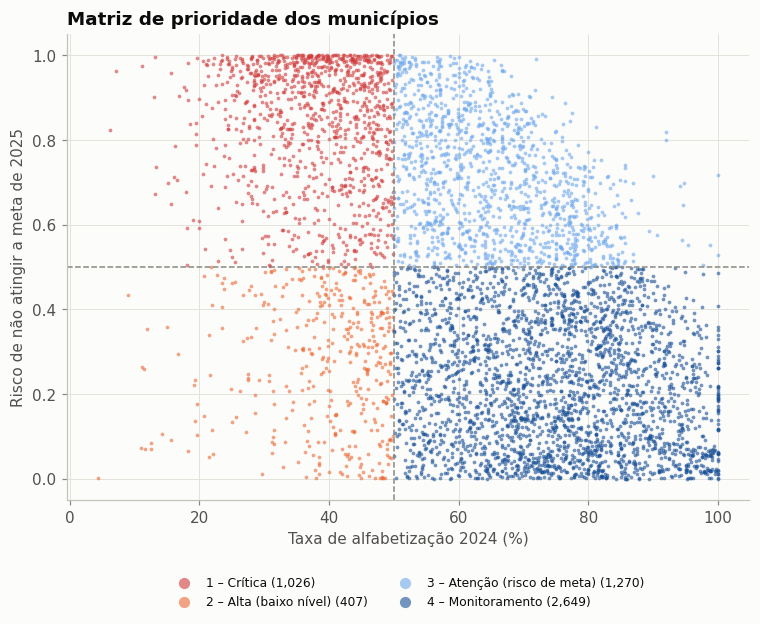

,municípios
prioridade,
1 – Crítica,1026
2 – Alta (baixo nível),407
3 – Atenção (risco de meta),1270
4 – Monitoramento,2649


In [11]:
proj["prioridade"] = prioridade(proj["taxa_atual"], proj["risco_meta_2025"])
# Vermelho e laranja para as prioridades de ação; azul para acompanhamento.
cores_prior = {"1 – Crítica": VERMELHO, "2 – Alta (baixo nível)": LARANJA,
               "3 – Atenção (risco de meta)": AZUL_MEDIO, "4 – Monitoramento": AZUL_ESCURO}
fig, ax = plt.subplots(figsize=(8, 5.5))
for p, cor in cores_prior.items():
    d = proj[proj["prioridade"] == p]
    ax.scatter(d["taxa_atual"], d["risco_meta_2025"], s=6, alpha=0.6, color=cor, label=f"{p} ({len(d):,})", linewidths=0)
ax.axvline(50, color=CINZA, linestyle="--", linewidth=1); ax.axhline(0.5, color=CINZA, linestyle="--", linewidth=1)
ax.set_xlabel("Taxa de alfabetização 2024 (%)"); ax.set_ylabel("Risco de não atingir a meta de 2025")
ax.set_title("Matriz de prioridade dos municípios")
ax.legend(markerscale=3, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False)
salvar(fig, "estrategia_05_matriz_prioridade")
plt.show()
proj["prioridade"].value_counts().sort_index().to_frame("municípios")

In [12]:
# Municípios de prioridade crítica, ordenados pelo risco (top 20).
colunas = ["id_municipio", "nome_municipio", "sigla_uf", "porte_municipio", "taxa_atual", "taxa_prevista_2025",
           "meta_alvo", "participacao_atual", "risco_meta_2025", "prioridade", "obs"]
ranking = proj.sort_values(["prioridade", "risco_meta_2025"], ascending=[True, False])[colunas]
ranking = ranking.rename(columns={"taxa_atual": "taxa_2024", "meta_alvo": "meta_2025",
                                  "participacao_atual": "participacao_2024"})
ranking.to_csv(REPORTS_DIR / "ranking_prioridade_municipios_2025.csv", index=False, encoding="utf-8-sig")
ranking.head(20).round(2)

,id_municipio,nome_municipio,sigla_uf,porte_municipio,taxa_2024,taxa_prevista_2025,meta_2025,participacao_2024,risco_meta_2025,prioridade,obs
1190,2412005,São Gonçalo do Amarante,RN,100–500 mil,32.48,36.00,61.37,76.62,1.0,1 – Crítica,
4614,4305108,Caxias do Sul,RS,100–500 mil,43.20,47.59,72.56,82.63,1.0,1 – Crítica,Incerteza adicional: recuperação pós-enchentes
1185,2411502,Santo Antônio,RN,20–100 mil,23.56,32.60,70.80,85.39,1.0,1 – Crítica,
4695,4309209,Gravataí,RS,100–500 mil,41.00,44.16,68.91,77.25,1.0,1 – Crítica,Incerteza adicional: recuperação pós-enchentes
4860,4316907,Santa Maria,RS,100–500 mil,39.70,45.55,70.02,77.89,1.0,1 – Crítica,Incerteza adicional: recuperação pós-enchentes
4890,4318705,São Leopoldo,RS,100–500 mil,37.20,40.94,64.51,71.70,1.0,1 – Crítica,Incerteza adicional: recuperação pós-enchentes
4789,4313409,Novo Hamburgo,RS,100–500 mil,36.00,44.51,68.07,83.60,1.0,1 – Crítica,Incerteza adicional: recuperação pós-enchentes
4972,4323002,Viamão,RS,100–500 mil,38.90,42.99,65.74,83.34,1.0,1 – Crítica,Incerteza adicional: recuperação pós-enchentes
4597,4304408,Canela,RS,20–100 mil,42.20,44.89,79.06,78.53,1.0,1 – Crítica,Incerteza adicional: recuperação pós-enchentes
4961,4322400,Uruguaiana,RS,100–500 mil,47.30,45.33,67.36,74.64,1.0,1 – Crítica,Incerteza adicional: recuperação pós-enchentes


In [13]:
# Concentração da prioridade crítica por UF.
crit = proj.assign(critica=proj["prioridade"] == "1 – Crítica").groupby("sigla_uf")["critica"].agg(["sum", "mean"])
crit.columns = ["municípios críticos", "% dos municípios da UF"]
crit.sort_values("municípios críticos", ascending=False).head(10).style.format({"% dos municípios da UF": "{:.1%}"})

,municípios críticos,% dos municípios da UF
sigla_uf,,
BA,336,84.4%
RS,187,42.4%
RN,75,49.7%
PA,71,50.0%
SP,56,8.9%
PB,54,24.4%
SE,44,58.7%
MA,29,13.4%
AM,29,52.7%


## 5. Quais regiões possuem padrões semelhantes? (Agrupamento)

K-Means sobre variáveis padronizadas de **desempenho** (taxa 2024 e variação) e de **contexto**
(IDHM, renda, pobreza, distorção idade-série, analfabetismo adulto, porte). O número de grupos é
escolhido pela **silhueta** e pelo **cotovelo** da inércia.

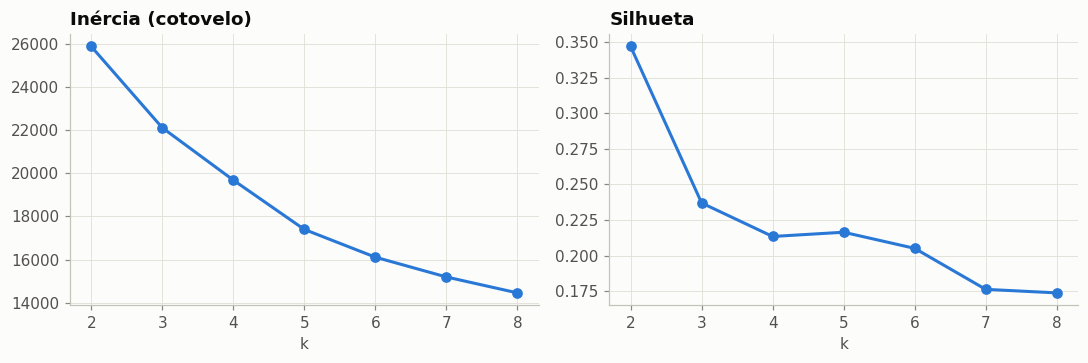

,inercia,silhueta
k,,
2,25884.973,0.347
3,22115.811,0.237
4,19687.917,0.213
5,17398.860,0.216
6,16111.378,0.205
7,15194.199,0.176
8,14455.394,0.174


In [14]:
ev = pd.read_parquet(ROOT / "data/processed/gold_municipio_evolucao.parquet")[["id_municipio", "taxa_alfabetizacao_2024", "variacao_taxa"]]
base_cl = projecao_mun.merge(ev, on="id_municipio", how="inner").rename(columns={"taxa_alfabetizacao_2024": "taxa_2024"})
base_cl = base_cl.dropna(subset=["taxa_2024", "variacao_taxa"])
Xc = base_cl[list(VARS_CLUSTER)]
selecao_k = escolher_k(Xc, range(2, 9))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(selecao_k.index, selecao_k["inercia"], marker="o", color=AZUL); axes[0].set_title("Inércia (cotovelo)")
axes[1].plot(selecao_k.index, selecao_k["silhueta"], marker="o", color=AZUL); axes[1].set_title("Silhueta")
for ax in axes: ax.set_xlabel("k")
fig.tight_layout(); salvar(fig, "estrategia_06_escolha_k"); plt.show()
selecao_k.round(3)

In [15]:
K = 5   # ver justificativa abaixo
cl = pipeline_cluster(K).fit(Xc)
base_cl["cluster"] = cl["kmeans"].labels_
perfil = perfil_clusters(base_cl)
nomes = nomear_clusters(perfil)
base_cl["perfil"] = base_cl["cluster"].map(nomes)
perfil.insert(0, "perfil", perfil.index.map(nomes))
perfil.round(2)

,perfil,municípios,taxa_2024,variacao_taxa,idhm,renda_per_capita,pct_extrema_pobreza,taxa_atraso_2anos_fund,taxa_analfabetismo_18mais,log_populacao
cluster,,,,,,,,,,
0,Queda recente de desempenho,845,56.30,-14.05,0.71,630.81,1.94,11.27,9.17,3.78
1,Supera o contexto,899,76.75,11.21,0.59,252.80,23.16,21.12,30.55,4.02
2,Desempenho intermediário (centros maiores),900,61.70,3.02,0.74,764.89,1.37,11.92,6.16,4.78
3,Vulnerabilidade social e educacional,1229,40.72,-1.33,0.58,265.90,21.43,25.43,27.55,4.15
4,Bom desempenho e contexto favorável,1523,78.02,9.48,0.69,537.07,3.05,13.58,12.07,3.85


**Escolha de k = 5:** a silhueta é maior com k = 2 e cai de forma suave depois disso, o que é comum em
dados socioeconômicos contínuos, em que os grupos não são bem separados. O cotovelo da inércia aparece
entre 4 e 5. A escolha de k = 5 privilegia **perfis interpretáveis e acionáveis**, incluindo o grupo que
supera o contexto, sem fragmentar demais os municípios. Os nomes vêm das medianas de cada grupo
(desempenho × IDHM), por regras simples definidas em `nomear_clusters()`.

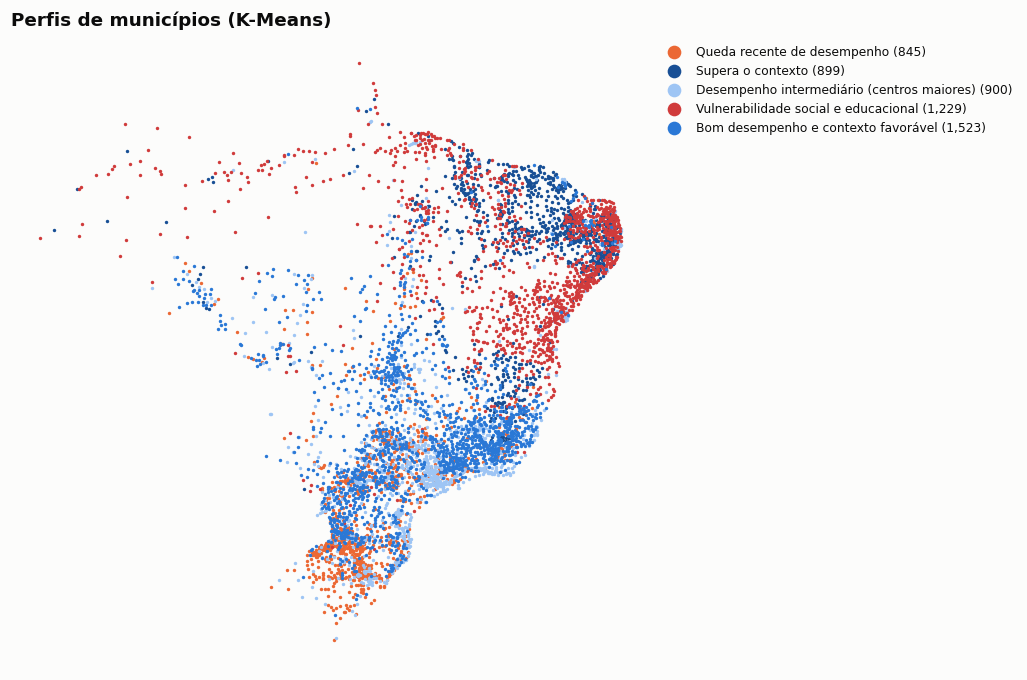

In [16]:
# Mapa dos perfis.
fig, ax = plt.subplots(figsize=(7.5, 7.5))
# Cores com significado: azul para desempenho bom/intermediário, laranja para queda, vermelho para vulnerabilidade.
def cor_perfil(nome):
    if nome.startswith("Supera o contexto"): return AZUL_ESCURO
    if nome.startswith("Bom desempenho"): return AZUL
    if nome.startswith("Desempenho intermediário"): return AZUL_CLARO
    if nome.startswith("Queda recente"): return LARANJA
    if nome.startswith("Vulnerabilidade"): return VERMELHO
    return CINZA
for c, nome in sorted(nomes.items()):
    cor = cor_perfil(nome)
    d = base_cl[base_cl["cluster"] == c]
    ax.scatter(d["longitude"], d["latitude"], s=5, color=cor, label=f"{nome} ({len(d):,})", linewidths=0)
ax.set_aspect("equal"); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
for s in ax.spines.values(): s.set_visible(False)
ax.legend(markerscale=4, fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
ax.set_title("Perfis de municípios (K-Means)")
salvar(fig, "estrategia_07_mapa_clusters")
plt.show()

In [17]:
# Composição regional de cada perfil (% dos municípios do perfil em cada região).
comp = pd.crosstab(base_cl["perfil"], base_cl["regiao"], normalize="index")
comp = comp[["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]]
(comp * 100).round(1)

regiao,Norte,Nordeste,Centro-Oeste,Sudeste,Sul
perfil,,,,,
Bom desempenho e contexto favorável,4.6,2.8,18.0,50.4,24.2
Desempenho intermediário (centros maiores),4.2,8.3,10.3,49.3,27.8
Queda recente de desempenho,3.2,1.1,7.3,28.9,59.5
Supera o contexto,5.8,79.8,1.7,12.8,0.0
Vulnerabilidade social e educacional,18.4,76.1,1.5,3.4,0.7


**Leitura dos perfis**
- **Supera o contexto** (899 municípios, 80% no Nordeste): IDHM baixo e pobreza alta, mas alfabetização
  mediana de 77% e em alta (+11 pontos). São os casos que mais sugerem que gestão e política educacional
  podem compensar o contexto, e uma referência para troca de práticas. A causa, porém, não é testada aqui.
- **Vulnerabilidade social e educacional** (1.229, Nordeste e Norte): alfabetização baixa (41%) e contexto
  adverso. Reúne 65% dos municípios de prioridade crítica.
- **Queda recente de desempenho** (845, 60% no Sul): contexto favorável, mas perda de 14 pontos em um ano.
  A queda coincide com as enchentes no RS. Pede **recomposição de aprendizagem**.
- **Desempenho intermediário (centros maiores)** e **Bom desempenho e contexto favorável**: municípios mais
  desenvolvidos. O primeiro grupo tem desempenho abaixo do que o contexto faria esperar.
- **Os perfis atravessam fronteiras estaduais:** municípios de UFs diferentes podem compartilhar o mesmo
  perfil e, portanto, a mesma estratégia.

In [18]:
# Perfis × prioridade: onde estão os municípios críticos?
cruz = pd.crosstab(base_cl.merge(proj[["id_municipio", "prioridade"]], on="id_municipio")["perfil"],
                   base_cl.merge(proj[["id_municipio", "prioridade"]], on="id_municipio")["prioridade"])
cruz

prioridade,1 – Crítica,2 – Alta (baixo nível),3 – Atenção (risco de meta),4 – Monitoramento
perfil,,,,
Bom desempenho e contexto favorável,1,27,239,1245
Desempenho intermediário (centros maiores),135,37,272,429
Queda recente de desempenho,208,57,433,126
Supera o contexto,3,26,128,734
Vulnerabilidade social e educacional,669,249,185,99


In [19]:
# Exporta a base municipal consolidada para uso em painéis (Power BI, Looker etc.).
saida = base_cl[["id_municipio", "perfil"]].merge(
    proj[["id_municipio", "nome_municipio", "sigla_uf", "regiao", "porte_municipio", "taxa_atual", "meta_alvo",
          "taxa_prevista_2025", "risco_meta_2025", "faixa_risco", "prioridade", "obs", "latitude", "longitude"]], on="id_municipio", how="right")
saida.to_csv(REPORTS_DIR / "municipios_risco_perfil_2025.csv", index=False, encoding="utf-8-sig")
print(f"{len(saida):,} municípios exportados para reports/municipios_risco_perfil_2025.csv")

5,352 municípios exportados para reports/municipios_risco_perfil_2025.csv


## 6. Síntese para a gestão pública

| Pergunta | Resposta |
|---|---|
| Quais municípios podem não atingir a meta de 2025? | O modelo prevê a taxa do ano seguinte e a probabilidade de ficar abaixo da meta (ROC-AUC ≈ 0,78 e R² ≈ 0,66 em municípios fora do treino), sem depender da escala da meta. A média prevista para 2025 (67%) ficou próxima do resultado nacional observado (66%). |
| Quais municípios apresentam maior risco educacional? | Os 1.026 de **prioridade crítica**: baixa alfabetização **e** alta chance de não atingir a meta. A lista está em `reports/ranking_prioridade_municipios_2025.csv`. |
| Quais regiões possuem padrões semelhantes? | Cinco perfis: **Supera o contexto** (80% no Nordeste), **Vulnerabilidade social e educacional** (Nordeste e Norte), **Queda recente** (60% no Sul, coincidindo com as enchentes no RS) e dois perfis de contexto favorável no Sul, no Sudeste e no Centro-Oeste. |

**Uso sugerido:** atualizar o modelo todo ano com o novo resultado da avaliação, revisar a lista de
prioridades com as secretarias estaduais e usar os municípios que superam o contexto como referência para
troca de experiências. As projeções são estimativas e devem ser lidas com a incerteza indicada, sobretudo
em municípios pequenos e no RS.